<a href="https://colab.research.google.com/github/Amartyesh/astrobiology-computational-journey/blob/main/Telescope%20FITS%20images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
from astropy.io import fits
from astropy import units as u

# 1. Working with physical astronomical units
distance_to_mars = 225e6 * u.km
light_travel_time = (distance_to_mars / (299792.458 * u.km / u.s)).to(u.min)
print(f"One-way light time to Mars: {light_travel_time:.2f}")

# 2. Creating a synthetic 2D astronomical image array and saving as FITS
synthetic_starfield = np.random.normal(loc=100, scale=15, size=(256, 256))
synthetic_starfield[128, 128] = 5000  # Simulated bright star at center

hdu = fits.PrimaryHDU(synthetic_starfield)
hdu.header['OBJECT'] = 'Synthetic_Field_01'
hdu.header['FILTER'] = 'H-Alpha'
hdu.writeto('test_observation.fits', overwrite=True)
print("FITS file created successfully with metadata header.")

One-way light time to Mars: 12.51 min
FITS file created successfully with metadata header.


In [1]:
from astropy.io import fits
from astropy.utils.data import download_file

fits_url = "http://data.astropy.org/tutorials/FITS-images/HorseHead.fits"
image_file = download_file(fits_url, cache=True)

with fits.open(image_file) as hdul:
    hdul.info()

Filename: /root/.astropy/cache/download/url/ff6e0b93871033c68022ca026a956d87/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     161   (891, 893)   int16   
  1  er.mask       1 TableHDU        25   1600R x 4C   [F6.2, F6.2, F6.2, F6.2]   


In [2]:
with fits.open(image_file) as hdul:
    header = hdul[0].header
    image_data = hdul[0].data

print("Target Object:", header.get('OBJECT', 'Unknown'))
print("Observation Date:", header.get('DATE-OBS', 'Unknown'))
print("Array Shape (Rows, Cols):", image_data.shape)
print("Pixel Data Type:", image_data.dtype)

Target Object: data
Observation Date: 1990-12-22T13:49:00
Array Shape (Rows, Cols): (893, 891)
Pixel Data Type: >i2


In [3]:
import numpy as np

print(f"Min pixel value:    {np.min(image_data)}")
print(f"Max pixel value:    {np.max(image_data)}")
print(f"Median (Sky level): {np.median(image_data)}")
print(f"Std Deviation:      {np.std(image_data):.2f}")

Min pixel value:    3759
Max pixel value:    22918
Median (Sky level): 9658.0
Std Deviation:      3032.39


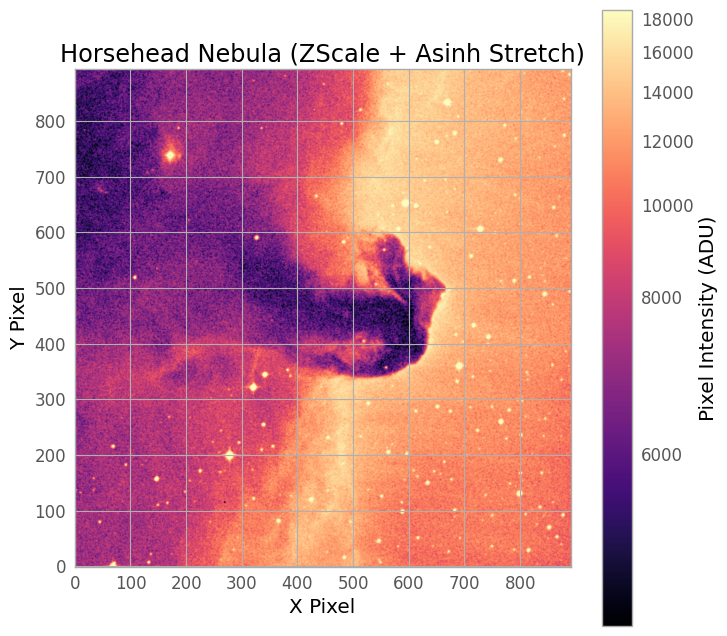

In [4]:
import matplotlib.pyplot as plt
from astropy.visualization import astropy_mpl_style, ImageNormalize, ZScaleInterval, AsinhStretch

plt.style.use(astropy_mpl_style)

norm = ImageNormalize(image_data, interval=ZScaleInterval(), stretch=AsinhStretch())

plt.figure(figsize=(8, 8))
plt.imshow(image_data, cmap='magma', origin='lower', norm=norm)
plt.colorbar(label='Pixel Intensity (ADU)')
plt.title("Horsehead Nebula (ZScale + Asinh Stretch)")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.show()

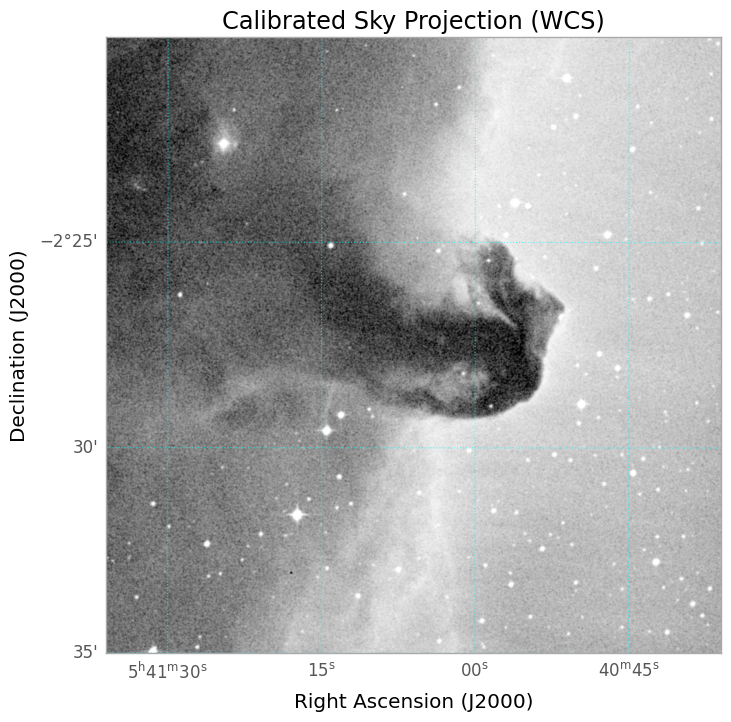

In [5]:
from astropy.wcs import WCS

wcs = WCS(header)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection=wcs)

ax.imshow(image_data, cmap='gray', origin='lower', norm=norm)
ax.coords.grid(True, color='cyan', ls='dotted', alpha=0.6)
ax.set_xlabel('Right Ascension (J2000)')
ax.set_ylabel('Declination (J2000)')
plt.title("Calibrated Sky Projection (WCS)")
plt.show()

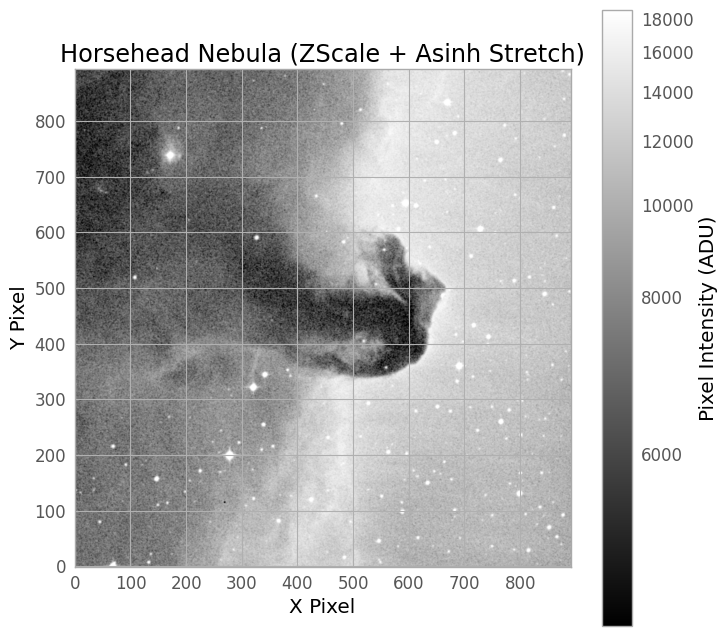

In [6]:
import matplotlib.pyplot as plt
from astropy.visualization import astropy_mpl_style, ImageNormalize, ZScaleInterval, AsinhStretch

plt.style.use(astropy_mpl_style)

norm = ImageNormalize(image_data, interval=ZScaleInterval(), stretch=AsinhStretch())

plt.figure(figsize=(8, 8))
plt.imshow(image_data, cmap='gray', origin='lower', norm=norm)
plt.colorbar(label='Pixel Intensity (ADU)')
plt.title("Horsehead Nebula (ZScale + Asinh Stretch)")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.show()

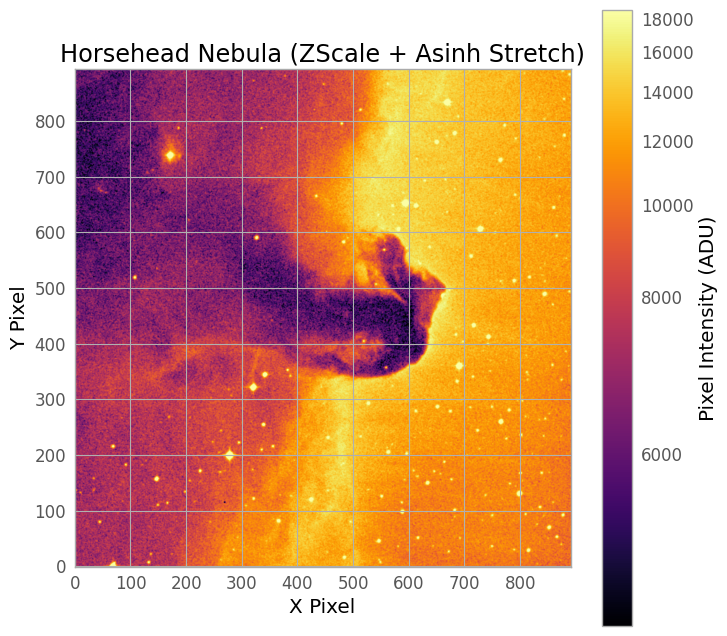

In [7]:
import matplotlib.pyplot as plt
from astropy.visualization import astropy_mpl_style, ImageNormalize, ZScaleInterval, AsinhStretch

plt.style.use(astropy_mpl_style)

norm = ImageNormalize(image_data, interval=ZScaleInterval(), stretch=AsinhStretch())

plt.figure(figsize=(8, 8))
plt.imshow(image_data, cmap='inferno', origin='lower', norm=norm)
plt.colorbar(label='Pixel Intensity (ADU)')
plt.title("Horsehead Nebula (ZScale + Asinh Stretch)")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.show()

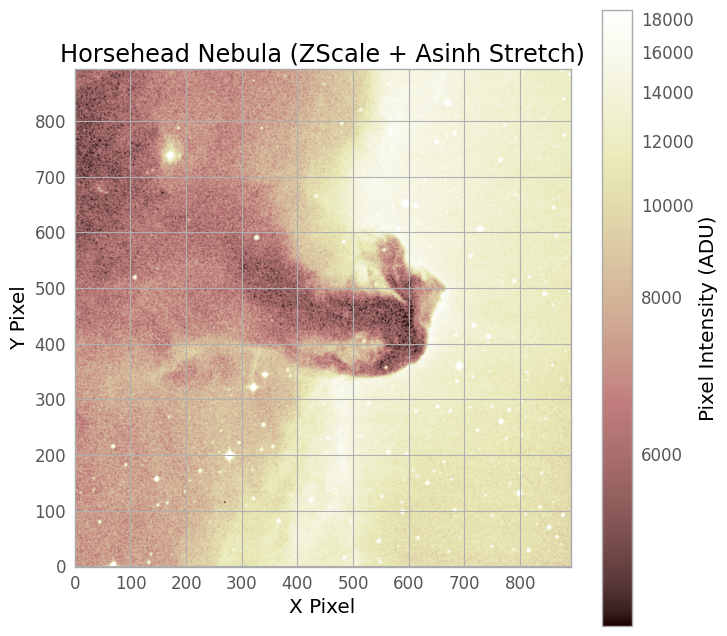

In [8]:
import matplotlib.pyplot as plt
from astropy.visualization import astropy_mpl_style, ImageNormalize, ZScaleInterval, AsinhStretch

plt.style.use(astropy_mpl_style)

norm = ImageNormalize(image_data, interval=ZScaleInterval(), stretch=AsinhStretch())

plt.figure(figsize=(8, 8))
plt.imshow(image_data, cmap='pink', origin='lower', norm=norm)
plt.colorbar(label='Pixel Intensity (ADU)')
plt.title("Horsehead Nebula (ZScale + Asinh Stretch)")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.show()

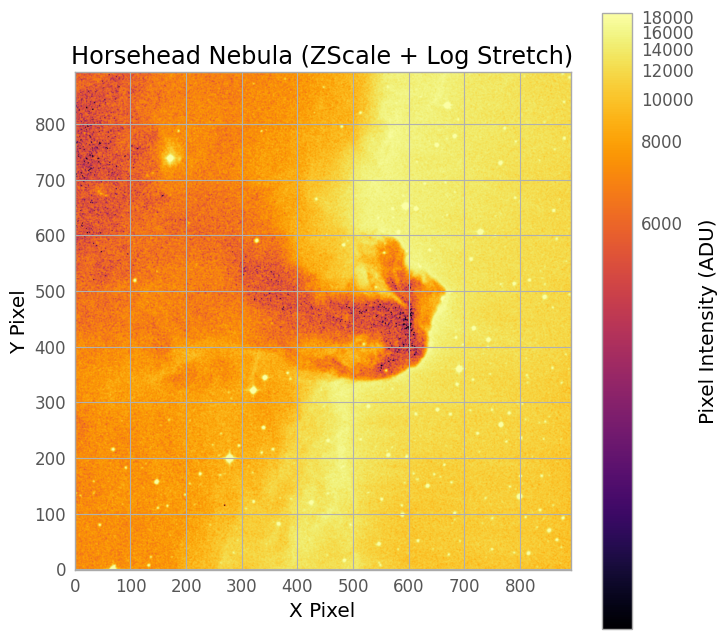

In [13]:
import matplotlib.pyplot as plt
from astropy.visualization import astropy_mpl_style, ImageNormalize, ZScaleInterval, LogStretch

plt.style.use(astropy_mpl_style)

norm = ImageNormalize(image_data, interval=ZScaleInterval(), stretch=LogStretch() )

plt.figure(figsize=(8, 8))
plt.imshow(image_data, cmap='inferno', origin='lower', norm=norm)
plt.colorbar(label='Pixel Intensity (ADU)')
plt.title("Horsehead Nebula (ZScale + Log Stretch)")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.show()

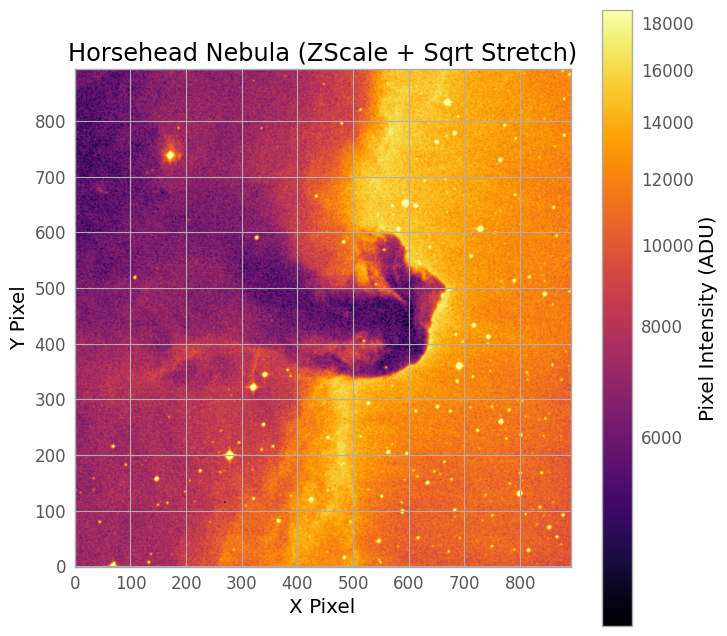

In [12]:
import matplotlib.pyplot as plt
from astropy.visualization import astropy_mpl_style, ImageNormalize, ZScaleInterval, SqrtStretch

plt.style.use(astropy_mpl_style)

norm = ImageNormalize(image_data, interval=ZScaleInterval(), stretch=SqrtStretch())

plt.figure(figsize=(8, 8))
plt.imshow(image_data, cmap='inferno', origin='lower', norm=norm)
plt.colorbar(label='Pixel Intensity (ADU)')
plt.title("Horsehead Nebula (ZScale + Sqrt Stretch)")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.show()

In [14]:
!pip install -q astroquery

In [15]:
from astroquery.skyview import SkyView
from astropy.io import fits
import astropy.units as u

# 1. Apna target nebula aur survey (telescope filter) chuno
target_name = "Orion Nebula"  # Yahan 'M1', 'M57', ya 'Carina Nebula' bhi likh sakte ho or any nebula of ur choice
survey_filter = "DSS2 Red"    # Digitized Sky Survey (Red optical filter)- tells which telescope filter to use

# 2. NASA SkyView archive se FITS file fetch karo
print(f"{target_name} ka data fetch ho raha hai...")
hdu_list = SkyView.get_images(
    position=target_name,
    survey=[survey_filter],
    pixels=600,               # 600x600 pixel cutout
    radius=0.5 * u.deg        # Aasmaan mein 0.5 degree ka field of view - to get zoom out view of that image
)

# 3. Pehli mili hui FITS file ka HDUList nikalo
hdul = hdu_list[0]
hdul.info()


hdul.writeto("my_nebula.fits", overwrite=True)
print("File 'my_nebula.fits' ke naam se save ho gayi!")

Orion Nebula ka data fetch ho raha hai...
Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     129   (600, 600)   float32   
File 'my_nebula.fits' ke naam se save ho gayi!


Sky Background Median: 10186.00
Peak Nebula/Star Flux: 22386.00
Estimated Peak SNR:    2.6


<function matplotlib.pyplot.show(close=None, block=None)>

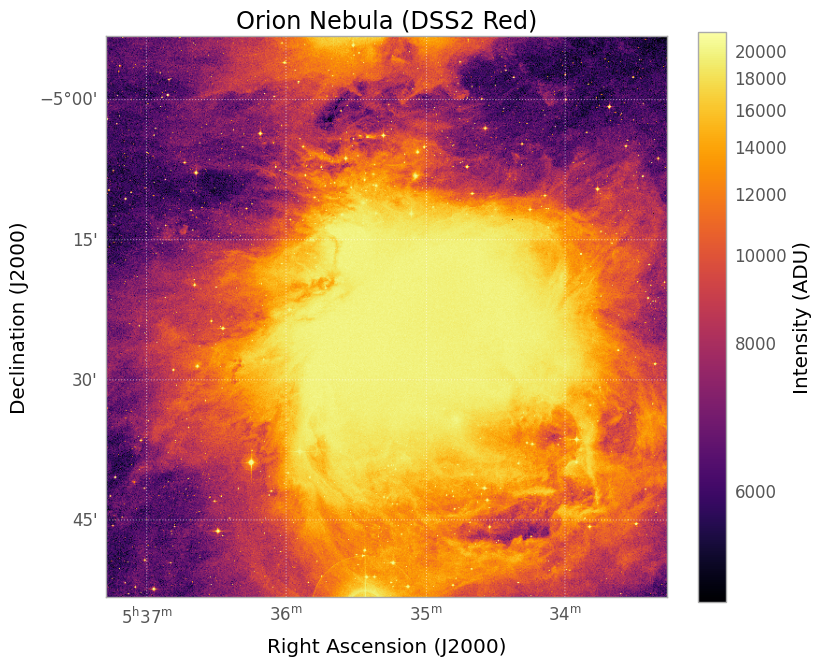

In [17]:
# numpy for maths ,matplotfor the plot , Imagenoramalize for viewing , zscaleintervale for fltering the nebula from bg sky noise , Asinhstretch to strecth or boost the faint image
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, ZScaleInterval, AsinhStretch
from astropy.wcs import WCS

# Header aur Pixel Matrix nikalo
header = hdul[0].header
data = hdul[0].data
wcs = WCS(header)

# 1. Quantitative Analysis: Signal-to-Noise Estimate
sky_median = np.median(data)
sky_std = np.std(data)
peak_brightness = np.max(data)
snr_estimate = (peak_brightness - sky_median) / sky_std

print(f"Sky Background Median: {sky_median:.2f}")
print(f"Peak Nebula/Star Flux: {peak_brightness:.2f}")
print(f"Estimated Peak SNR:    {snr_estimate:.1f}")

# 2. Visual Render with WCS Coordinates- to get the position
norm = ImageNormalize(data, interval=ZScaleInterval(), stretch=AsinhStretch())

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection=wcs)
im = ax.imshow(data, cmap='inferno', origin='lower', norm=norm)

ax.coords.grid(True, color='white', ls='dotted', alpha=0.5)
ax.set_xlabel('Right Ascension (J2000)')
ax.set_ylabel('Declination (J2000)')
plt.title(f"{target_name} ({survey_filter})")
plt.colorbar(im, ax=ax, label='Intensity (ADU)', fraction=0.046)
plt.show

In [18]:
from astroquery.skyview import SkyView
from astropy.io import fits
import astropy.units as u

# 1. Apna target nebula aur survey (telescope filter) chuno- selected the nebula/cluster and telescope filter red/blue
target_name = "Crab Nebula"  # Yahan 'M1', 'M57', ya 'Carina Nebula' bhi likh sakte ho
survey_filter = "DSS2 Red"    # Digitized Sky Survey (Red optical filter)

# 2. NASA SkyView archive se FITS file fetch karo- use net to fetch info from skyview-find coordinate of that obj from SIMBAD dayabase and send FITS image back
print(f"{target_name} ka data fetch ho raha hai...")
hdu_list = SkyView.get_images(
    position=target_name,
    survey=[survey_filter],
    pixels=600,               # 600x600 pixel cutout
    radius=0.5 * u.deg        # Aasmaan mein 0.5 degree ka field of view
)

# 3. Pehli mili hui FITS file ka HDUList nikalo
hdul = hdu_list[0]
hdul.info()

# Optional: Ise apne Colab folder mein save karne ke liye
hdul.writeto("my_nebula.fits", overwrite=True)
print("File 'my_nebula.fits' ke naam se save ho gayi!")

Crab Nebula ka data fetch ho raha hai...
Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     129   (600, 600)   float32   
File 'my_nebula.fits' ke naam se save ho gayi!


Sky Background Median: 4351.00
Peak Nebula/Star Flux: 24897.00
Estimated Peak SNR:    14.3


<function matplotlib.pyplot.show(close=None, block=None)>

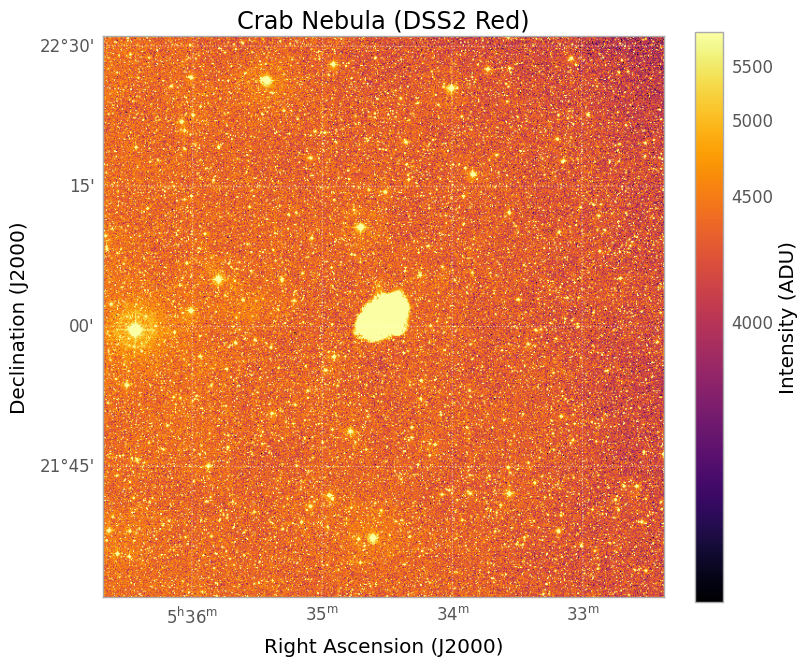

In [19]:
# numpy for maths ,matplotfor the plot , Imagenoramalize for viewing , zscaleintervale for fltering the nebula from bg sky noise , Asinhstretch to strecth or boost the faint image
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, ZScaleInterval, AsinhStretch
from astropy.wcs import WCS

# Header aur Pixel Matrix nikalo
header = hdul[0].header
data = hdul[0].data
wcs = WCS(header)

# 1. Quantitative Analysis: Signal-to-Noise Estimate
sky_median = np.median(data)
sky_std = np.std(data)
peak_brightness = np.max(data)
snr_estimate = (peak_brightness - sky_median) / sky_std

print(f"Sky Background Median: {sky_median:.2f}")
print(f"Peak Nebula/Star Flux: {peak_brightness:.2f}")
print(f"Estimated Peak SNR:    {snr_estimate:.1f}")

# 2. Visual Render with WCS Coordinates- to get the position
norm = ImageNormalize(data, interval=ZScaleInterval(), stretch=AsinhStretch())

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection=wcs)
im = ax.imshow(data, cmap='inferno', origin='lower', norm=norm)

ax.coords.grid(True, color='white', ls='dotted', alpha=0.5)
ax.set_xlabel('Right Ascension (J2000)')
ax.set_ylabel('Declination (J2000)')
plt.title(f"{target_name} ({survey_filter})")
plt.colorbar(im, ax=ax, label='Intensity (ADU)', fraction=0.046)
plt.show

In [36]:
from astroquery.skyview import SkyView
from astropy.io import fits
import astropy.units as u

# 1. Apna target nebula aur survey (telescope filter) chuno- selected the nebula/cluster and telescope filter red/blue
target_name = "M57"  # Yahan 'M1', 'M57', ya 'Carina Nebula' bhi likh sakte ho
survey_filter = "DSS2 Red"    # Digitized Sky Survey (Red optical filter)

# 2. NASA SkyView archive se FITS file fetch karo- use net to fetch info from skyview-find coordinate of that obj from SIMBAD dayabase and send FITS image back
print(f"{target_name} ka data fetch ho raha hai...")
hdu_list = SkyView.get_images(
    position=target_name,
    survey=[survey_filter],
    pixels=600,               # 600x600 pixel cutout
    radius=0.1 * u.deg        # Aasmaan mein 0.5 degree ka field of view
)

# 3. Pehli mili hui FITS file ka HDUList nikalo
hdul = hdu_list[0]
hdul.info()

# Optional: Ise apne Colab folder mein save karne ke liye
hdul.writeto("my_nebula.fits", overwrite=True)
print("File 'my_nebula.fits' ke naam se save ho gayi!")

M57 ka data fetch ho raha hai...
Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     129   (600, 600)   float32   
File 'my_nebula.fits' ke naam se save ho gayi!


Sky Background Median: 2701.00
Peak Nebula/Star Flux: 22341.00
Estimated Peak SNR:    8.8


<function matplotlib.pyplot.show(close=None, block=None)>

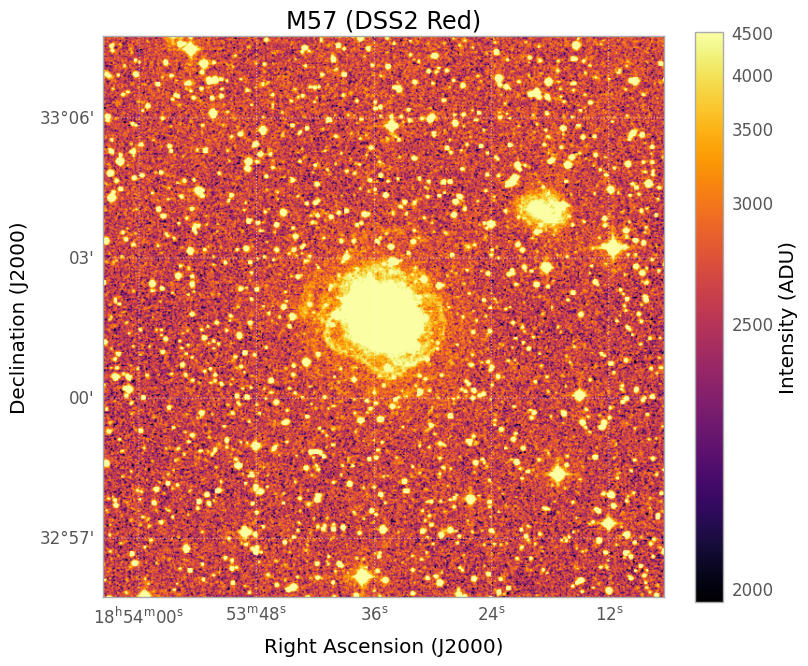

In [37]:
# numpy for maths ,matplotfor the plot , Imagenoramalize for viewing , zscaleintervale for fltering the nebula from bg sky noise , Asinhstretch to strecth or boost the faint image
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, ZScaleInterval, AsinhStretch
from astropy.wcs import WCS

# Header aur Pixel Matrix nikalo
header = hdul[0].header
data = hdul[0].data
wcs = WCS(header)

# 1. Quantitative Analysis: Signal-to-Noise Estimate
sky_median = np.median(data)
sky_std = np.std(data)
peak_brightness = np.max(data)
snr_estimate = (peak_brightness - sky_median) / sky_std

print(f"Sky Background Median: {sky_median:.2f}")
print(f"Peak Nebula/Star Flux: {peak_brightness:.2f}")
print(f"Estimated Peak SNR:    {snr_estimate:.1f}")

# 2. Visual Render with WCS Coordinates- to get the position
norm = ImageNormalize(data, interval=ZScaleInterval(), stretch=AsinhStretch())

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection=wcs)
im = ax.imshow(data, cmap='inferno', origin='lower', norm=norm)

ax.coords.grid(True, color='white', ls='dotted', alpha=0.5)
ax.set_xlabel('Right Ascension (J2000)')
ax.set_ylabel('Declination (J2000)')
plt.title(f"{target_name} ({survey_filter})")
plt.colorbar(im, ax=ax, label='Intensity (ADU)', fraction=0.046)
plt.show